In [1]:
!pip -q install numpy pandas matplotlib firebase-admin

In [2]:
!python /content/greenhouse_edge.py

РГР - варіант 2. Звіт з моделювання теплиці
Записів у SQLite: 1095
Частка pH в умовному діапазоні 6,0-7,0: 96.35 %
Кореляція температура / вологість ґрунту: -0.532
Найкраще стиснення: bzip2

Сезонні середні:
        temperature_c  soil_moisture_pct  illuminance_lux  soil_ph
season                                                            
Весна           22.54              52.73         14966.98     6.52
Зима            10.52              60.16          5315.91     6.54
Літо            26.71              50.19         18204.14     6.53
Осінь           14.97              57.10          8500.39     6.52

Порівняння ділянок:
           temperature_c  soil_moisture_pct  illuminance_lux  soil_ph
site                                                                 
Ділянка A          17.98              51.98         12500.15     6.34
Ділянка B          18.93              54.73         11603.01     6.54
Ділянка C          19.31              58.33         11269.81     6.71

Стиснення:
{
  "gz

In [3]:

!zip -r /content/RGR_results.zip /content/results


  adding: content/results/ (stored 0%)
  adding: content/results/firebase_status.txt (deflated 19%)
  adding: content/results/cleaned.json.zlib (stored 0%)
  adding: content/results/quality.json (deflated 24%)
  adding: content/results/cleaned.json.gz (stored 0%)
  adding: content/results/temperature_moisture.png (deflated 5%)
  adding: content/results/compression.json (deflated 56%)
  adding: content/results/greenhouse.sqlite (deflated 71%)
  adding: content/results/site_comparison.png (deflated 25%)
  adding: content/results/report.txt (deflated 55%)
  adding: content/results/raw.csv (deflated 59%)
  adding: content/results/seasonal_temperature.png (deflated 10%)
  adding: content/results/firebase_upload_payload.json (deflated 88%)
  adding: content/results/cleaned.csv (deflated 75%)
  adding: content/results/cleaned.json.bz2 (deflated 0%)
  adding: content/results/ph_histogram.png (deflated 18%)


In [4]:

from google.colab import files
files.download("/content/RGR_results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:

import os
import glob

keys = glob.glob("/content/*firebase-adminsdk*.json")
assert len(keys) == 1, "Не найден ключ Firebase или загружено несколько ключей"

os.environ["FIREBASE_SERVICE_ACCOUNT_JSON"] = keys[0]

os.environ["FIREBASE_DATABASE_URL"] = (
    "https://rgr-iot-variant-2-default-rtdb."
    "europe-west1.firebasedatabase.app"
)

print("Настройки Firebase подготовлены")


Настройки Firebase подготовлены


In [7]:
!python /content/greenhouse_edge.py

РГР - варіант 2. Звіт з моделювання теплиці
Записів у SQLite: 1095
Частка pH в умовному діапазоні 6,0-7,0: 96.35 %
Кореляція температура / вологість ґрунту: -0.532
Найкраще стиснення: bzip2

Сезонні середні:
        temperature_c  soil_moisture_pct  illuminance_lux  soil_ph
season                                                            
Весна           22.54              52.73         14966.98     6.52
Зима            10.52              60.16          5315.91     6.54
Літо            26.71              50.19         18204.14     6.53
Осінь           14.97              57.10          8500.39     6.52

Порівняння ділянок:
           temperature_c  soil_moisture_pct  illuminance_lux  soil_ph
site                                                                 
Ділянка A          17.98              51.98         12500.15     6.34
Ділянка B          18.93              54.73         11603.01     6.54
Ділянка C          19.31              58.33         11269.81     6.71

Стиснення:
{
  "gz

In [8]:

from pathlib import Path

status = Path("/content/results/firebase_status.txt")

if status.exists():
    print(status.read_text(encoding="utf-8"))
else:
    print("Файл статуса Firebase не найден")


Успішна передача і повторне отримання 1095 записів.


In [9]:

import json
import pandas as pd
from pathlib import Path

file = Path("/content/results/firebase_download.json")

if file.exists():
    with open(file, encoding="utf-8") as f:
        data = json.load(f)

    df = pd.DataFrame(data)
    print("Завантажено записів із Firebase:", len(df))
    display(df.head(10))
else:
    print("Файл не знайдений")


Завантажено записів із Firebase: 1095


,date,illuminance_lux,ph_optimal,season,site,soil_moisture_pct,soil_ph,temperature_c
0,2025-01-01,287.998,True,Зима,Ділянка A,59.091,6.615,6.363
1,2025-01-02,4061.595,True,Зима,Ділянка A,59.386,6.307,7.504
2,2025-01-03,5077.304,True,Зима,Ділянка A,57.417,6.233,8.112
3,2025-01-04,3641.748,True,Зима,Ділянка A,50.948,6.475,10.325
4,2025-01-05,7874.956,True,Зима,Ділянка A,54.228,6.116,12.539
5,2025-01-06,7427.710,True,Зима,Ділянка A,61.936,6.182,11.497
6,2025-01-07,6866.573,True,Зима,Ділянка A,60.270,6.389,7.386
7,2025-01-08,6546.922,True,Зима,Ділянка A,60.676,6.765,11.811
8,2025-01-09,6837.574,True,Зима,Ділянка A,65.766,6.224,15.791
9,2025-01-10,5633.960,True,Зима,Ділянка A,56.187,6.595,8.552


In [10]:

print("СТАТИСТИЧНИЙ ЗВІТ - ВАРІАНТ 2")

print("\n1. Загальна статистика:")
display(df.describe())

print("\n2. Середні показники за сезонами:")
display(
    df.groupby("season")[
        ["temperature_c", "soil_moisture_pct",
         "illuminance_lux", "soil_ph"]
    ].mean().round(2)
)

print("\n3. Порівняння ділянок:")
display(
    df.groupby("site")[
        ["temperature_c", "soil_moisture_pct",
         "illuminance_lux", "soil_ph"]
    ].mean().round(2)
)

print("\n4. Кореляція температури та вологості:")
print(
    df["temperature_c"].corr(
        df["soil_moisture_pct"]
    ).round(3)
)

print("\n5. Частка оптимальних значень pH:")
print(round(df["ph_optimal"].mean() * 100, 2), "%")


СТАТИСТИЧНИЙ ЗВІТ - ВАРІАНТ 2

1. Загальна статистика:


,illuminance_lux,soil_moisture_pct,soil_ph,temperature_c
count,1095.000000,1095.000000,1095.000000,1095.000000
mean,11790.988321,55.011600,6.526451,18.740744
std,6125.910662,7.061791,0.242206,7.406287
min,0.000000,33.435000,5.811000,3.538000
25%,6652.406500,50.231000,6.362500,12.044500
50%,11670.243000,55.103000,6.533000,18.728000
75%,17017.934500,59.976000,6.694500,25.394000
max,26188.448000,73.801000,7.300000,34.788000



2. Середні показники за сезонами:


,temperature_c,soil_moisture_pct,illuminance_lux,soil_ph
season,,,,
Весна,22.54,52.73,14966.98,6.52
Зима,10.52,60.16,5315.91,6.54
Літо,26.71,50.19,18204.14,6.53
Осінь,14.97,57.10,8500.39,6.52



3. Порівняння ділянок:


,temperature_c,soil_moisture_pct,illuminance_lux,soil_ph
site,,,,
Ділянка A,17.98,51.98,12500.15,6.34
Ділянка B,18.93,54.73,11603.01,6.54
Ділянка C,19.31,58.33,11269.81,6.71



4. Кореляція температури та вологості:
-0.532

5. Частка оптимальних значень pH:
96.35 %


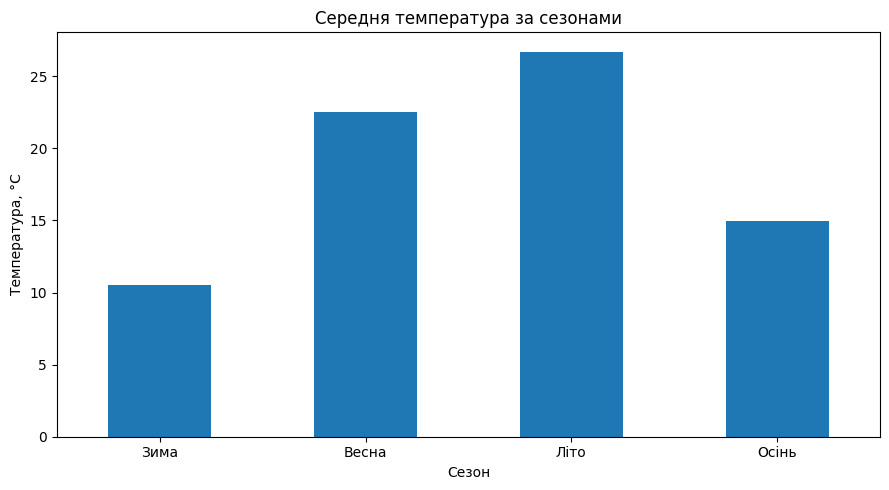

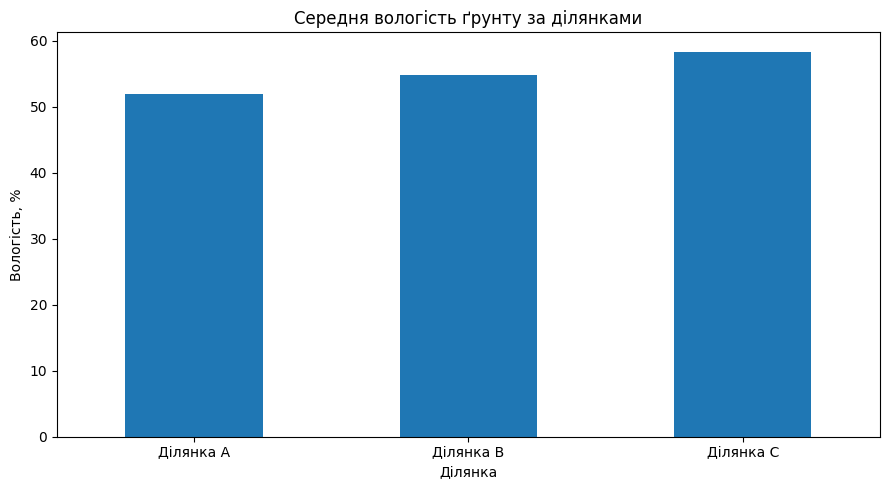

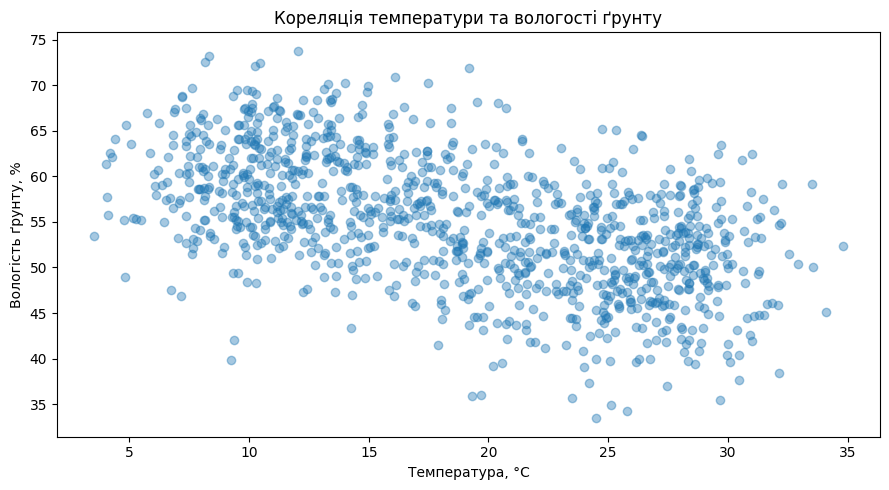

In [11]:

import matplotlib.pyplot as plt
import pandas as pd

# 1. Сезонные изменения температуры
season_order = ["Зима", "Весна", "Літо", "Осінь"]
seasonal = df.groupby("season")["temperature_c"].mean()
seasonal = seasonal.reindex(season_order)

plt.figure(figsize=(9, 5))
seasonal.plot(kind="bar")
plt.title("Середня температура за сезонами")
plt.xlabel("Сезон")
plt.ylabel("Температура, °C")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 2. Сравнение участков по влажности
plt.figure(figsize=(9, 5))
df.groupby("site")["soil_moisture_pct"].mean().plot(kind="bar")
plt.title("Середня вологість ґрунту за ділянками")
plt.xlabel("Ділянка")
plt.ylabel("Вологість, %")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 3. Корреляция температуры и влажности
plt.figure(figsize=(9, 5))
plt.scatter(
    df["temperature_c"],
    df["soil_moisture_pct"],
    alpha=0.4
)
plt.title("Кореляція температури та вологості ґрунту")
plt.xlabel("Температура, °C")
plt.ylabel("Вологість ґрунту, %")
plt.tight_layout()
plt.show()
